# CAS Predictive Modeling Competition: Model Fitting, Evaluation and Rating Factors

## Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import patsy
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import mean_tweedie_deviance
from sklearn.model_selection import StratifiedGroupKFold

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
COV_ORDER = ["PP", "ALE", "GM", "LIAB"]
SEEDS = [11, 22, 33]

## 1. Data: one row per student × coverage

In [2]:
raw = pd.read_csv("C:/Users/ELITEBOOK 840 G5/OneDrive - The University of Texas at El Paso/CAS Predictive Modelling/Comp files/06 - CAS Predictive Modeling Case Competition- Dataset.csv")

# Cap each Guest Medical and Liability claim at $50k before aggregating
is_capped_cov = raw["coverage"].isin(["Guest Medical", "Liability"])
raw["amount_capped"] = np.where(is_capped_cov, np.minimum(raw["amount"], 50_000), raw["amount"])

md = (raw.groupby(["student_id", "coverage"], as_index=False)
         .agg(n=("claim_id", lambda s: (s > 0).sum()),
              loss=("amount", "sum"),
              loss_capped=("amount_capped", "sum"),
              **{c: (c, "first") for c in ["class", "study", "gpa", "greek", "distance_to_campus",
                                           "sprinklered", "training_holdout"]}))
md["cov"] = md["coverage"].map({"Personal Property": "PP", "Additional Living Expense": "ALE",
                                "Guest Medical": "GM", "Liability": "LIAB"})

## 2. Rating variables

In [3]:
def add_features(d):
    d = d.copy()
    d["tier"] = d["class"].map({"Freshman": "1", "Sophomore": "1", "Junior": "2",
                                "Senior": "3", "Grad student": "3"})
    d["class_adj"] = d["class"].map({"Freshman": "Base", "Junior": "Base", "Senior": "Base",
                                     "Sophomore": "Sophomore", "Grad student": "Grad"})
    d["dist_band"] = pd.cut(d["distance_to_campus"], [-np.inf, 0, 1, 3, 6, np.inf],
                            labels=["On campus", "Off 0-1mi", "Off 1-3mi", "Off 3-6mi", "Off 6+mi"]).astype(str)
    d["gpa_band"] = pd.cut(d["gpa"], [0, 1, 2, 3, 4.01], right=False,
                           labels=["<1.0", "1.0-2.0", "2.0-3.0", "3.0+"]).astype(str)
    d["sprinklered"] = np.where(d["sprinklered"].astype(bool), "Yes", "No")

    # Indicator columns for the interaction terms
    flags = {"greek": d["greek"].eq("Greek"),
             "off": d["dist_band"].ne("On campus"),
             "nospr": d["sprinklered"].eq("No"),
             "gpa_lt1": d["gpa_band"].eq("<1.0"),
             "gpa_1to2": d["gpa_band"].eq("1.0-2.0"),
             "gpa_3plus": d["gpa_band"].eq("3.0+")}
    for name, flag in flags.items():
        for c in ["ALE", "GM", "LIAB"]:
            d[f"{name}_x_{c}"] = (flag & d["cov"].eq(c)).astype(float)
    for g in ["gpa_lt1", "gpa_1to2", "gpa_3plus"]:
        d[f"greek_x_{g}"] = (flags["greek"] & flags[g]).astype(float)
    return d


md = add_features(md)
train = md[md.training_holdout.eq("training")].reset_index(drop=True)
hold = md[md.training_holdout.eq("holdout")].reset_index(drop=True)

## 3. Model formulas

In [4]:
TERMS = {
    "coverage":      "C(cov, Treatment('PP'))",
    "tier":          "C(tier, Treatment('1'))",
    "class_adj":     "C(class_adj, Treatment('Base'))",
    "study":         "C(study, Treatment('Business'))",
    "greek":         "C(greek, Treatment('Non-greek'))",
    "dist_band":     "C(dist_band, Treatment('On campus'))",
    "sprinklered":   "C(sprinklered, Treatment('Yes'))",
    "gpa_band":      "C(gpa_band, Treatment('2.0-3.0'))",
    "greek x cov":   "greek_x_ALE + greek_x_GM + greek_x_LIAB",
    "off x cov":     "off_x_ALE + off_x_GM + off_x_LIAB",
    "nospr x cov":   "nospr_x_ALE + nospr_x_GM + nospr_x_LIAB",
    "gpa<1 x cov":   "gpa_lt1_x_ALE + gpa_lt1_x_GM + gpa_lt1_x_LIAB",
    "gpa1-2 x cov":  "gpa_1to2_x_ALE + gpa_1to2_x_GM + gpa_1to2_x_LIAB",
    "gpa3+ x cov":   "gpa_3plus_x_ALE + gpa_3plus_x_GM + gpa_3plus_x_LIAB",
    "greek x gpa":   "greek_x_gpa_lt1 + greek_x_gpa_1to2 + greek_x_gpa_3plus",
}
MAIN = ["coverage", "tier", "class_adj", "study", "greek", "dist_band", "sprinklered", "gpa_band"]
INTER = ["greek x cov", "off x cov", "nospr x cov", "gpa<1 x cov", "gpa1-2 x cov", "gpa3+ x cov", "greek x gpa"]
REDUCED = [k for k in MAIN if k != "study"] + ["off x cov"]


def rhs(keys):
    return " + ".join(TERMS[k] for k in keys)

## 4. Candidate models

In [5]:
def fit_rating(raw_fit, df):
    """Fit on capped loss, then per coverage: rebalance to capped actuals and load back the excess."""
    predict = raw_fit(df)
    g = df.assign(p=predict(df)).groupby("cov")
    balance = g["loss_capped"].sum() / g["p"].sum()
    excess_load = g["loss"].sum() / g["loss_capped"].sum()
    return lambda X: predict(X) * X["cov"].map(balance * excess_load).values


def fit_flat(df):
    means = df.groupby("cov")["loss_capped"].mean()
    return lambda X: X["cov"].map(means).values


def fit_tier(df):
    means = df.groupby(["cov", "tier"])["loss_capped"].mean()
    return lambda X: means.reindex(pd.MultiIndex.from_frame(X[["cov", "tier"]])).values


def tweedie(keys):
    def fit(df):
        res = smf.glm(f"loss_capped ~ {rhs(keys)}", data=df,
                      family=sm.families.Tweedie(var_power=1.5, link=sm.families.links.Log())).fit()
        return lambda X: np.asarray(res.predict(X))
    return fit


def fit_freq_sev(df, keys):
    freq = smf.glm(f"n ~ {rhs(keys)}", data=df, family=sm.families.Poisson()).fit()
    claims = df[df.n > 0].assign(sev=lambda d: d.loss_capped / d.n)
    sev = smf.glm(f"sev ~ {rhs(keys)}", data=claims, var_weights=claims["n"],
                  family=sm.families.Gamma(link=sm.families.links.Log())).fit()
    return freq, sev


def freq_sev(keys):
    def fit(df):
        freq, sev = fit_freq_sev(df, keys)
        return lambda X: np.asarray(freq.predict(X)) * np.asarray(sev.predict(X))
    return fit


MODELS = {
    "M0 Flat":                  fit_flat,
    "M1 Tier only":             fit_tier,
    "M2 Tweedie main":          tweedie(MAIN),
    "M3 Tweedie + inter":       tweedie(MAIN + INTER),
    "M4 Freq x Sev":            freq_sev(MAIN + INTER),
    "M5 Freq x Sev reduced":    freq_sev(REDUCED),
    "M6 M5 + GPA3+ x cov":      freq_sev(REDUCED + ["gpa3+ x cov"]),
    "M7 Tweedie reduced":       tweedie(REDUCED),
    "M8 M5 + Greek x GPA":      freq_sev(REDUCED + ["greek x gpa"]),
    "M9 M7 + Greek x GPA":      tweedie(REDUCED + ["greek x gpa"]),
}
PROPOSED = "M5 Freq x Sev reduced"

## 5. Metrics

In [6]:
def gini(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    order = np.lexsort((np.random.default_rng(0).random(len(pred)), pred))   # random tie-break for M0
    cum_loss = np.r_[0, np.cumsum(actual[order]) / actual.sum()]
    return 1 - (cum_loss[:-1] + cum_loss[1:]).mean()   # 1 - 2 x area under the Lorenz curve


def student_level(df, pred_col):
    return df.groupby("student_id").agg(actual=("loss", "sum"), pred=(pred_col, "sum"))


def score(df, pred):
    d = df.assign(p=pred)
    s = student_level(d, "p")
    out = {"tweedie_dev": mean_tweedie_deviance(d["loss"], np.maximum(d["p"], 1e-9), power=1.5),
           "gini_student": gini(s["actual"], s["pred"]),
           "bias": d["p"].sum() / d["loss"].sum() - 1}
    for c in COV_ORDER:
        out[f"gini_{c}"] = gini(d.loc[d["cov"].eq(c), "loss"], d.loc[d["cov"].eq(c), "p"])
    return out

## 6. Grouped cross-validation (5 folds × 3 repeats, training data)

In [7]:
had_claim = train["student_id"].map(train.groupby("student_id")["n"].sum().gt(0))
for name in MODELS:
    train[f"oof {name}"] = 0.0

cv_rows = []
for seed in SEEDS:
    folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for k, (tr, te) in enumerate(folds.split(train, had_claim, groups=train["student_id"])):
        for name, spec in MODELS.items():
            p = fit_rating(spec, train.iloc[tr])(train.iloc[te])
            train.loc[te, f"oof {name}"] += p / len(SEEDS)
            cv_rows.append({"model": name, "seed": seed, "fold": k, **score(train.iloc[te], p)})

cv = pd.DataFrame(cv_rows)
cv.drop(columns=["seed", "fold"]).groupby("model").mean().round(3)

,tweedie_dev,gini_student,bias,gini_PP,gini_ALE,gini_GM,gini_LIAB
model,,,,,,,
M0 Flat,91.4300,-0.0150,0.0100,-0.0230,0.0090,-0.0290,-0.0370
M1 Tier only,91.8040,0.0350,0.0100,-0.0220,0.0810,-0.0230,-0.0090
M2 Tweedie main,81.6480,0.4670,0.0100,0.4190,0.4600,0.4730,0.4720
M3 Tweedie + inter,82.8950,0.4650,0.0090,0.4230,0.4500,0.4520,0.3840
M4 Freq x Sev,82.4030,0.4730,0.0110,0.4290,0.4530,0.4670,0.3800
M5 Freq x Sev reduced,81.2100,0.4740,0.0090,0.4260,0.4630,0.4830,0.4780
M6 M5 + GPA3+ x cov,81.4430,0.4730,0.0090,0.4250,0.4570,0.4800,0.4530
M7 Tweedie reduced,81.4310,0.4710,0.0110,0.4190,0.4620,0.4770,0.4850
M8 M5 + Greek x GPA,81.1780,0.4750,0.0090,0.4280,0.4610,0.4880,0.4760


### Paired comparison against M5 (same 15 folds)

In [8]:
dev = cv.pivot_table(index=["seed", "fold"], columns="model", values="tweedie_dev")
gin = cv.pivot_table(index=["seed", "fold"], columns="model", values="gini_student")

pd.DataFrame({
    "dev diff vs M5 (+ = M5 better)": dev.sub(dev[PROPOSED], axis=0).mean(),
    "folds M5 lower dev": dev.gt(dev[PROPOSED], axis=0).sum(),
    "Gini diff vs M5 (+ = M5 better)": -gin.sub(gin[PROPOSED], axis=0).mean(),
    "folds M5 higher Gini": gin.lt(gin[PROPOSED], axis=0).sum(),
}).drop(PROPOSED).round(3)

,dev diff vs M5 (+ = M5 better),folds M5 lower dev,Gini diff vs M5 (+ = M5 better),folds M5 higher Gini
model,,,,
M0 Flat,10.2200,15,0.4890,15
M1 Tier only,10.5950,15,0.4390,15
M2 Tweedie main,0.4380,11,0.0070,10
M3 Tweedie + inter,1.6860,15,0.0090,11
M4 Freq x Sev,1.1930,15,0.0020,10
M6 M5 + GPA3+ x cov,0.2340,14,0.0010,11
M7 Tweedie reduced,0.2220,9,0.0030,8
M8 M5 + Greek x GPA,-0.0320,6,-0.0010,5
M9 M7 + Greek x GPA,0.3110,13,0.0040,10


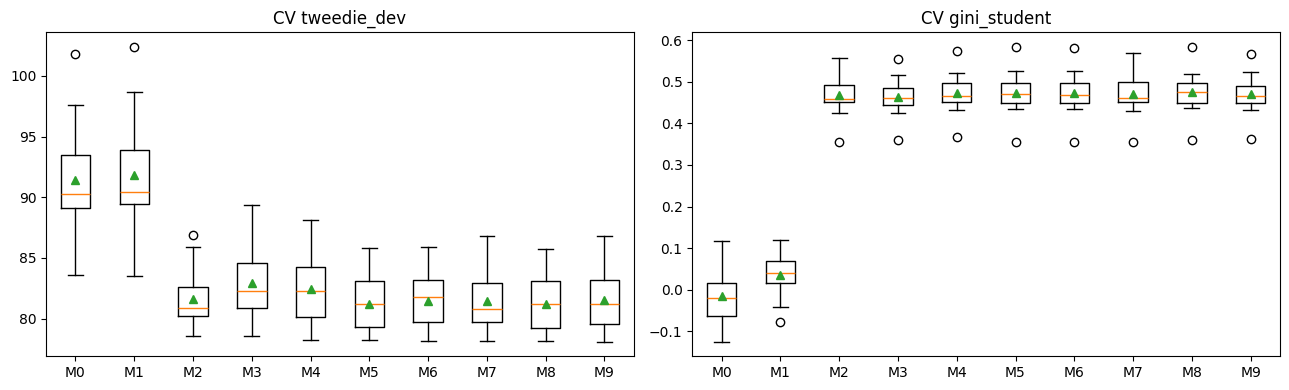

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["tweedie_dev", "gini_student"]):
    ax.boxplot([cv.loc[cv.model.eq(m), metric] for m in MODELS], labels=[m.split()[0] for m in MODELS], showmeans=True)
    ax.set_title(f"CV {metric}")
plt.tight_layout()
plt.show()

## 7. Lift diagnostics (out-of-fold)

### Lorenz curves

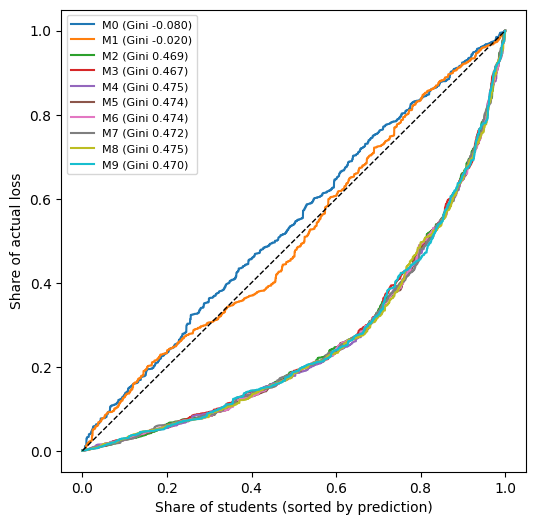

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
for name in MODELS:
    s = student_level(train, f"oof {name}").sort_values("pred")
    ax.plot(np.linspace(0, 1, len(s) + 1), np.r_[0, s["actual"].cumsum() / s["actual"].sum()],
            label=f"{name.split()[0]} (Gini {gini(s['actual'], s['pred']):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("Share of students (sorted by prediction)")
ax.set_ylabel("Share of actual loss")
ax.legend(fontsize=8)
plt.show()

### Decile lift

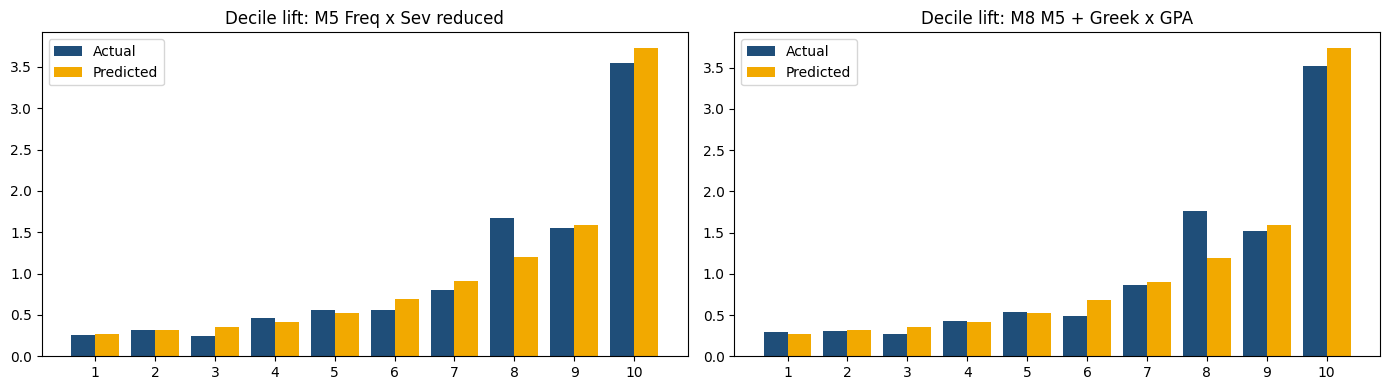

In [11]:
def quantile_lift(df, pred_col, q=10):
    s = student_level(df, pred_col)
    s["bucket"] = pd.qcut(s["pred"].rank(method="first"), q, labels=range(1, q + 1))
    return s.groupby("bucket", observed=True)[["actual", "pred"]].mean() / s["actual"].mean()


def plot_lift(t, title, ax):
    x = np.arange(len(t))
    ax.bar(x - 0.2, t["actual"], 0.4, label="Actual", color="#1f4e79")
    ax.bar(x + 0.2, t["pred"], 0.4, label="Predicted", color="#f2a900")
    ax.set_xticks(x, t.index)
    ax.set_title(title)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, [PROPOSED, "M8 M5 + Greek x GPA"]):
    plot_lift(quantile_lift(train, f"oof {name}"), f"Decile lift: {name}", ax)
plt.tight_layout()
plt.show()

### Top decile / bottom decile

In [12]:
top_bottom = {}
for name in MODELS:
    t = quantile_lift(train, f"oof {name}")["actual"]
    top_bottom[name] = t.iloc[-1] / t.iloc[0]
pd.Series(top_bottom).round(2)

M0 Flat                  0.5500
M1 Tier only             0.6300
M2 Tweedie main         13.2200
M3 Tweedie + inter      12.3400
M4 Freq x Sev           12.3900
M5 Freq x Sev reduced   13.5800
M6 M5 + GPA3+ x cov     14.0200
M7 Tweedie reduced      13.5000
M8 M5 + Greek x GPA     12.1900
M9 M7 + Greek x GPA     11.6100
dtype: float64

### Quintile lift by coverage

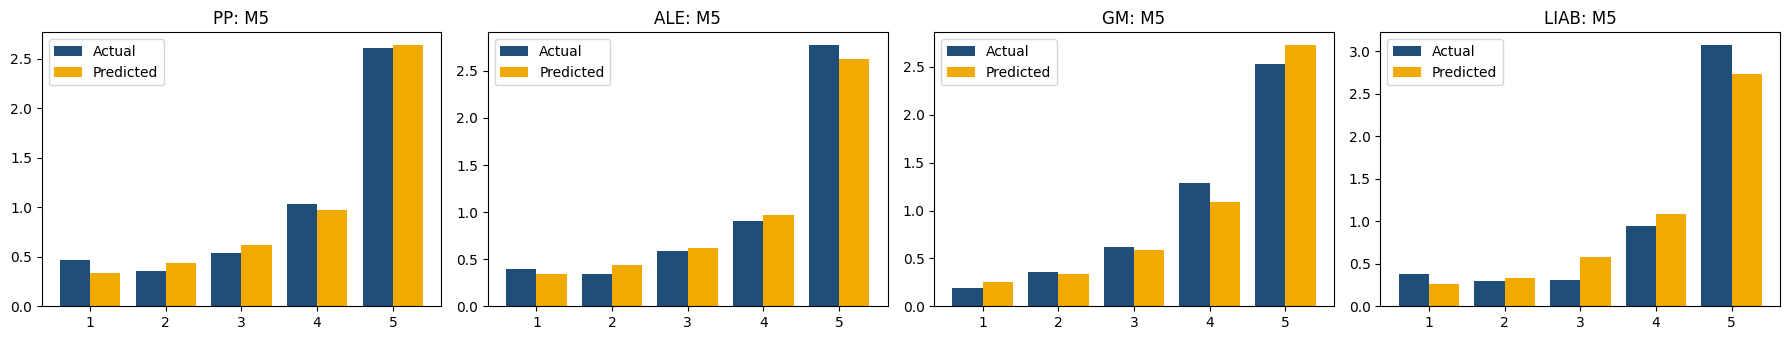

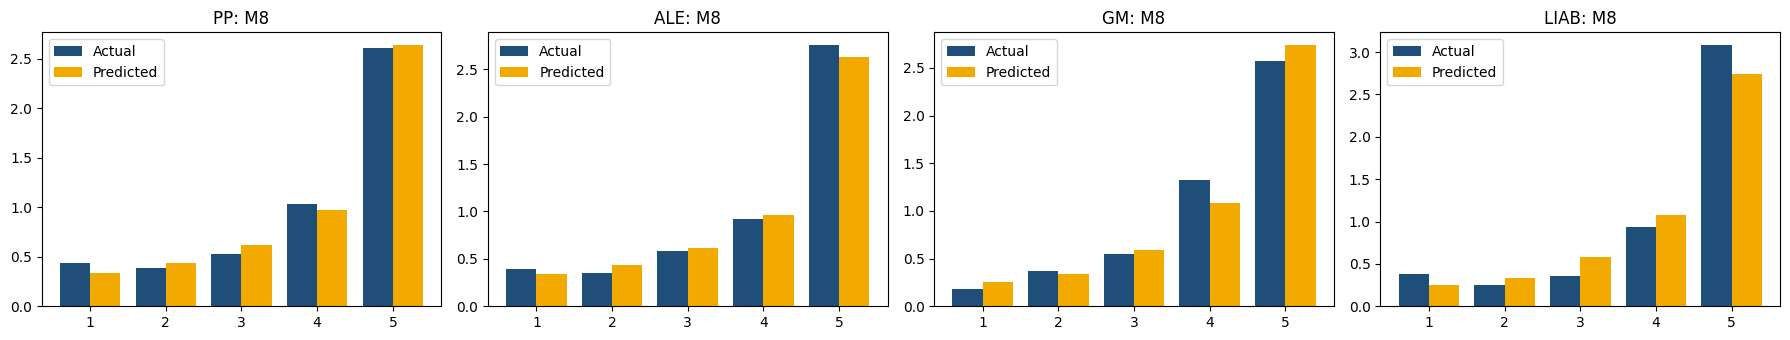

In [13]:
def coverage_lift(df, pred_col, cov, q=5):
    d = df.loc[df["cov"].eq(cov), ["loss", pred_col]].set_axis(["actual", "pred"], axis=1)
    d["bucket"] = pd.qcut(d["pred"].rank(method="first"), q, labels=range(1, q + 1))
    return d.groupby("bucket", observed=True).mean() / d["actual"].mean()


for name in [PROPOSED, "M8 M5 + Greek x GPA"]:
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
    for ax, c in zip(axes, COV_ORDER):
        plot_lift(coverage_lift(train, f"oof {name}", c), f"{c}: {name.split()[0]}", ax)
    plt.tight_layout()
    plt.show()

### Double lift

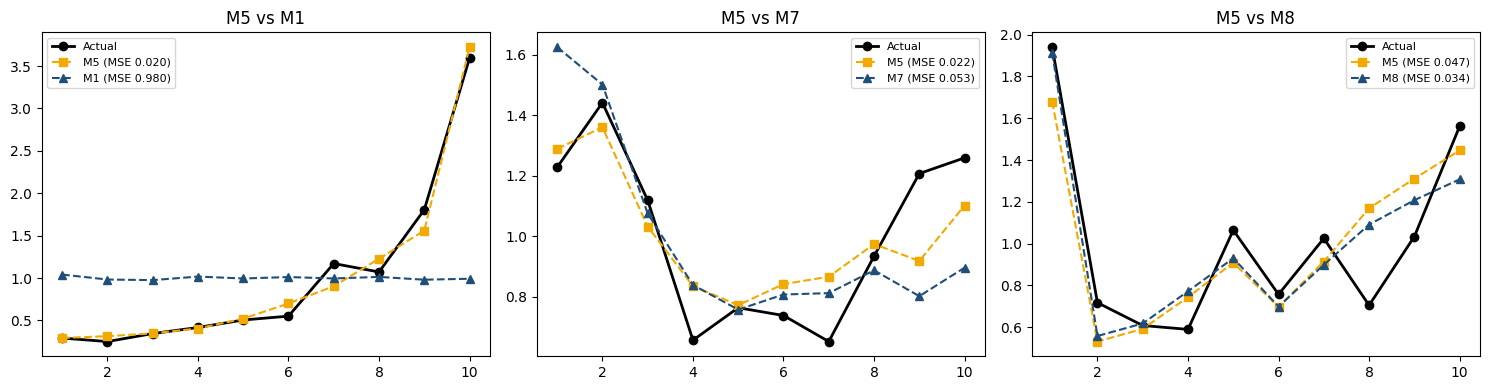

In [14]:
def double_lift(df, col_a, col_b, q=10):
    s = df.groupby("student_id").agg(actual=("loss", "sum"), a=(col_a, "sum"), b=(col_b, "sum"))
    s["bucket"] = pd.qcut((s["a"] / s["b"]).rank(method="first"), q, labels=range(1, q + 1))
    return s.groupby("bucket", observed=True)[["actual", "a", "b"]].mean() / s["actual"].mean()


def plot_double_lift(t, name_a, name_b, ax):
    mse = lambda col: ((t[col] - t["actual"]) ** 2).mean()
    ax.plot(t.index, t["actual"], "o-", color="black", lw=2, label="Actual")
    ax.plot(t.index, t["a"], "s--", color="#f2a900", label=f"{name_a} (MSE {mse('a'):.3f})")
    ax.plot(t.index, t["b"], "^--", color="#1f4e79", label=f"{name_b} (MSE {mse('b'):.3f})")
    ax.set_title(f"{name_a} vs {name_b}")
    ax.legend(fontsize=8)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, other in zip(axes, ["M1 Tier only", "M7 Tweedie reduced", "M8 M5 + Greek x GPA"]):
    plot_double_lift(double_lift(train, f"oof {PROPOSED}", f"oof {other}"), "M5", other.split()[0], ax)
plt.tight_layout()
plt.show()

### Actual / expected by rating variable (M5)

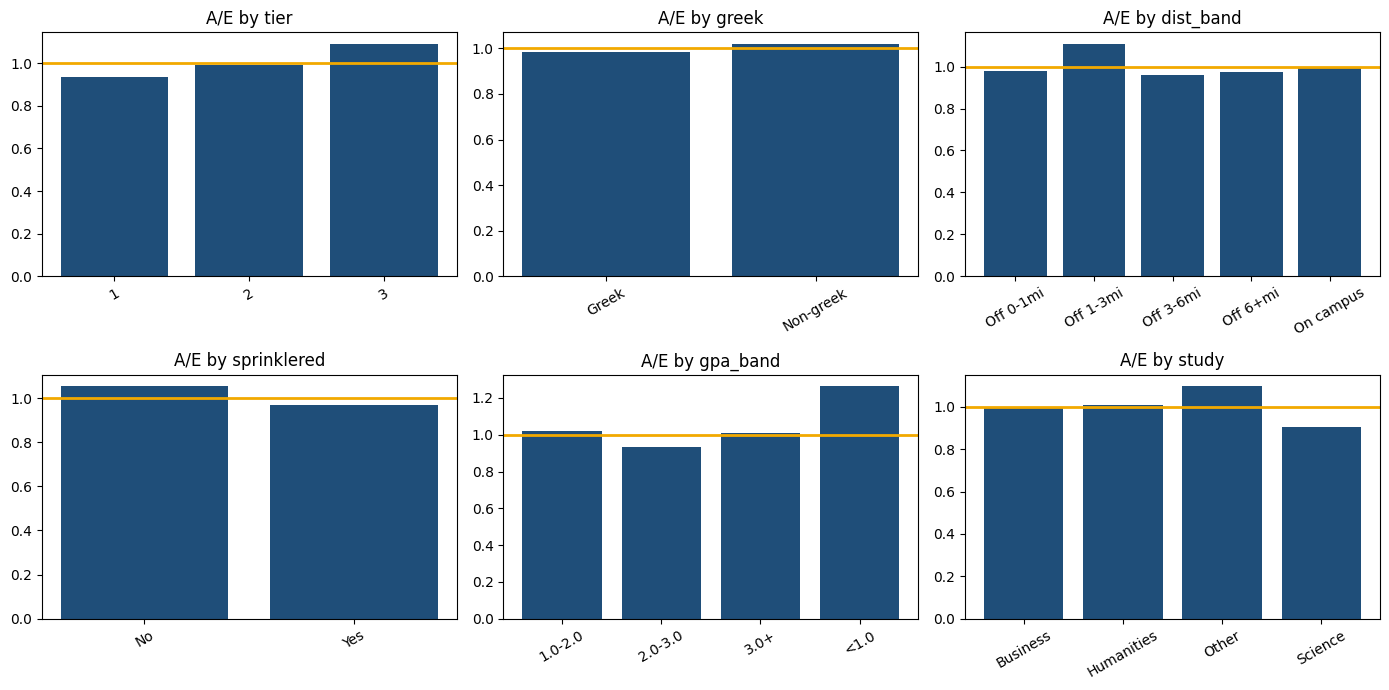

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, var in zip(axes.ravel(), ["tier", "greek", "dist_band", "sprinklered", "gpa_band", "study"]):
    g = train.groupby(var)[["loss", f"oof {PROPOSED}"]].sum()
    ax.bar(g.index, g["loss"] / g[f"oof {PROPOSED}"], color="#1f4e79")
    ax.axhline(1, color="#f2a900", lw=2)
    ax.set_title(f"A/E by {var}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 8. Likelihood-ratio tests (full design, training data)

In [15]:
freq_full, sev_full = fit_freq_sev(train, MAIN + INTER)
sev_data = train[train.n > 0].assign(sev=lambda d: d.loss_capped / d.n)

DROP = {
    "tier": ["tier"],
    "class_adj": ["class_adj"],
    "study": ["study"],
    "greek (+ interactions)": ["greek", "greek x cov", "greek x gpa"],
    "dist_band (+ off x cov)": ["dist_band", "off x cov"],
    "sprinklered (+ x cov)": ["sprinklered", "nospr x cov"],
    "gpa_band (+ interactions)": ["gpa_band", "gpa<1 x cov", "gpa1-2 x cov", "gpa3+ x cov", "greek x gpa"],
    **{f"{k} only": [k] for k in INTER},
}


def lr_test(full, keys, response, data, family, **kw):
    red = smf.glm(f"{response} ~ {rhs(keys)}", data=data, family=family, **kw).fit()
    df_diff = int(red.df_resid - full.df_resid)
    chi2 = (red.deviance - full.deviance) / full.scale
    return {"df": df_diff, "chi2": chi2, "p": stats.chi2.sf(chi2, df_diff)}


rows = {}
for term, drop in DROP.items():
    keys = [k for k in MAIN + INTER if k not in drop]
    f = lr_test(freq_full, keys, "n", train, sm.families.Poisson())
    s = lr_test(sev_full, keys, "sev", sev_data, sm.families.Gamma(link=sm.families.links.Log()),
                var_weights=sev_data["n"])
    rows[term] = {"df": f["df"], "freq chi2": f["chi2"], "freq p": f["p"], "sev chi2": s["chi2"], "sev p": s["p"]}
pd.DataFrame(rows).T.round(4)

,df,freq chi2,freq p,sev chi2,sev p
tier,2.0000,7.8243,0.0200,33.9733,0.0000
class_adj,2.0000,4.4064,0.1104,26.9374,0.0000
study,3.0000,6.2148,0.1016,0.9116,0.8226
greek (+ interactions),7.0000,183.6398,0.0000,490.4494,0.0000
dist_band (+ off x cov),7.0000,50.1132,0.0000,208.0977,0.0000
sprinklered (+ x cov),4.0000,1.6311,0.8032,154.7296,0.0000
gpa_band (+ interactions),15.0000,21.7491,0.1146,26.7376,0.0309
greek x cov only,3.0000,1.6053,0.6582,3.3636,0.3389
off x cov only,3.0000,8.1983,0.0421,1.4339,0.6976
nospr x cov only,3.0000,1.4509,0.6937,5.1910,0.1583


### Joint test: M5 vs full design

In [16]:
pd.DataFrame({
    "frequency": lr_test(freq_full, REDUCED, "n", train, sm.families.Poisson()),
    "severity": lr_test(sev_full, REDUCED, "sev", sev_data, sm.families.Gamma(link=sm.families.links.Log()),
                        var_weights=sev_data["n"]),
}).T.round(4)

,df,chi2,p
frequency,21.0000,25.7712,0.2153
severity,21.0000,34.6140,0.0311


## 9. Test evaluation

In [17]:
for name, spec in MODELS.items():
    hold[f"pred {name}"] = fit_rating(spec, train)(hold)

pd.DataFrame({name: score(hold, hold[f"pred {name}"]) for name in MODELS}).T.round(3)

,tweedie_dev,gini_student,bias,gini_PP,gini_ALE,gini_GM,gini_LIAB
M0 Flat,91.3070,-0.0340,0.0470,0.0970,0.0170,-0.0840,-0.1430
M1 Tier only,91.6910,0.0250,0.0430,-0.0160,-0.0080,0.0280,-0.0890
M2 Tweedie main,84.4160,0.3850,0.1190,0.3260,0.4190,0.3280,0.5460
M3 Tweedie + inter,84.9590,0.3780,0.1280,0.3230,0.4220,0.2940,0.5270
M4 Freq x Sev,84.3060,0.3910,0.1180,0.3300,0.4310,0.2990,0.5590
M5 Freq x Sev reduced,83.8820,0.4050,0.1030,0.3340,0.4400,0.3270,0.5690
M6 M5 + GPA3+ x cov,83.9340,0.4040,0.1030,0.3320,0.4440,0.3260,0.5590
M7 Tweedie reduced,84.4090,0.3930,0.1150,0.3290,0.4330,0.3170,0.5370
M8 M5 + Greek x GPA,84.1300,0.3980,0.1060,0.3340,0.4340,0.3220,0.5400
M9 M7 + Greek x GPA,84.8190,0.3880,0.1220,0.3310,0.4250,0.3100,0.5090


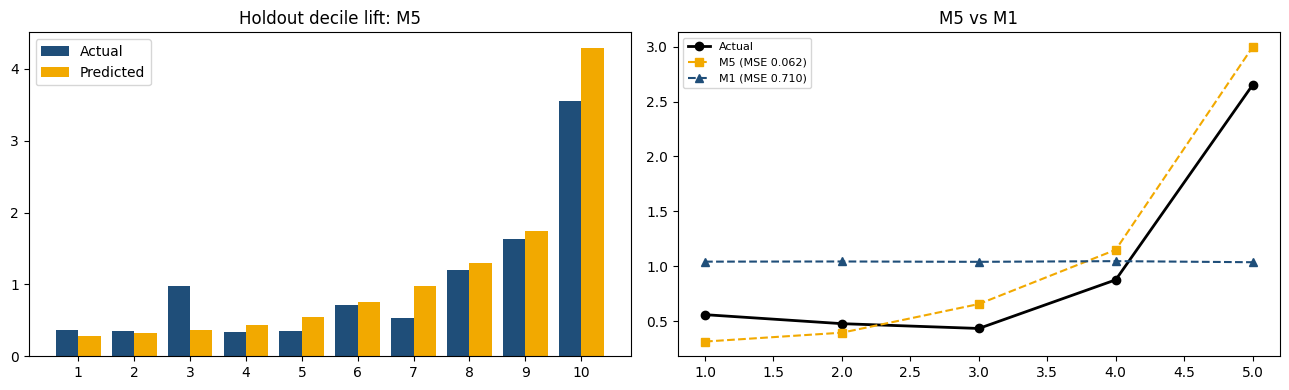

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_lift(quantile_lift(hold, f"pred {PROPOSED}"), "Holdout decile lift: M5", axes[0])
plot_double_lift(double_lift(hold, f"pred {PROPOSED}", "pred M1 Tier only", q=5), "M5", "M1", axes[1])
plt.tight_layout()
plt.show()

## 10. Final M5 on all 10,000 students

In [19]:
freq_final, sev_final = fit_freq_sev(md, REDUCED)
final = fit_rating(freq_sev(REDUCED), md)

### Coefficients

In [21]:
def coef_table(res):
    ci = res.conf_int()
    return pd.DataFrame({"coef": res.params, "se": res.bse, "exp(coef)": np.exp(res.params),
                         "lo95": np.exp(ci[0]), "hi95": np.exp(ci[1]), "p": res.pvalues})


coef_table(freq_final).round(3)

,coef,se,exp(coef),lo95,hi95,p
Intercept,-2.5110,0.0680,0.0810,0.0710,0.0930,0.0000
"C(cov, Treatment('PP'))[T.ALE]",-0.6000,0.0690,0.5490,0.4790,0.6290,0.0000
"C(cov, Treatment('PP'))[T.GM]",-1.5350,0.0980,0.2150,0.1780,0.2610,0.0000
"C(cov, Treatment('PP'))[T.LIAB]",-2.6580,0.1620,0.0700,0.0510,0.0960,0.0000
"C(tier, Treatment('1'))[T.2]",-0.0750,0.0680,0.9280,0.8120,1.0610,0.2720
"C(tier, Treatment('1'))[T.3]",-0.1600,0.0690,0.8520,0.7430,0.9760,0.0210
"C(class_adj, Treatment('Base'))[T.Grad]",-0.0780,0.0940,0.9250,0.7700,1.1120,0.4080
"C(class_adj, Treatment('Base'))[T.Sophomore]",-0.0990,0.0680,0.9060,0.7930,1.0350,0.1460
"C(greek, Treatment('Non-greek'))[T.Greek]",0.7600,0.0490,2.1390,1.9410,2.3560,0.0000
"C(dist_band, Treatment('On campus'))[T.Off 0-1mi]",0.2520,0.0940,1.2870,1.0700,1.5480,0.0070


In [22]:
coef_table(sev_final).round(3)

,coef,se,exp(coef),lo95,hi95,p
Intercept,6.1180,0.0420,454.1110,418.1960,493.1100,0.0000
"C(cov, Treatment('PP'))[T.ALE]",1.6140,0.0430,5.0230,4.6140,5.4690,0.0000
"C(cov, Treatment('PP'))[T.GM]",2.6900,0.0610,14.7370,13.0680,16.6190,0.0000
"C(cov, Treatment('PP'))[T.LIAB]",2.0590,0.1010,7.8340,6.4250,9.5520,0.0000
"C(tier, Treatment('1'))[T.2]",0.2430,0.0430,1.2750,1.1730,1.3870,0.0000
"C(tier, Treatment('1'))[T.3]",0.2610,0.0430,1.2980,1.1920,1.4140,0.0000
"C(class_adj, Treatment('Base'))[T.Grad]",0.2520,0.0590,1.2870,1.1470,1.4440,0.0000
"C(class_adj, Treatment('Base'))[T.Sophomore]",0.0890,0.0430,1.0930,1.0050,1.1880,0.0380
"C(greek, Treatment('Non-greek'))[T.Greek]",0.7110,0.0310,2.0370,1.9160,2.1650,0.0000
"C(dist_band, Treatment('On campus'))[T.Off 0-1mi]",0.4300,0.0580,1.5370,1.3700,1.7230,0.0000


### Base loss cost by tier × coverage

In [24]:
def profile(cov, **changes):
    base = {"cov": cov, "class": "Freshman", "study": "Business", "gpa": 2.5,
            "greek": "Non-greek", "distance_to_campus": 0.0, "sprinklered": True}
    return add_features(pd.DataFrame([{**base, **changes}]))


base_rates = pd.DataFrame({cov: {tier: final(profile(cov, **{"class": cls}))[0]
                                 for tier, cls in [(1, "Freshman"), (2, "Junior"), (3, "Senior")]}
                           for cov in COV_ORDER})
base_rates

,PP,ALE,GM,LIAB
1,36.1755,106.6471,123.7265,20.5515
2,42.8052,126.1916,146.4011,24.3179
3,40.0094,117.9497,136.8392,22.7296


### Rating factors by coverage (with 95% CI)

In [25]:
# (label, change from base student, reference student)
LEVELS = [
    ("class_adj", "Sophomore",      {"class": "Sophomore"},    {}),
    ("class_adj", "Grad (vs Senior)", {"class": "Grad student"}, {"class": "Senior"}),
    ("greek",     "Greek",          {"greek": "Greek"},        {}),
    ("dist_band", "Off 0-1mi",      {"distance_to_campus": 0.5}, {}),
    ("dist_band", "Off 1-3mi",      {"distance_to_campus": 2.0}, {}),
    ("dist_band", "Off 3-6mi",      {"distance_to_campus": 4.5}, {}),
    ("dist_band", "Off 6+mi",       {"distance_to_campus": 10.0}, {}),
    ("spr",       "No",             {"sprinklered": False},    {}),
    ("gpa_band",  "<1.0",           {"gpa": 0.5},              {}),
    ("gpa_band",  "1.0-2.0",        {"gpa": 1.5},              {}),
    ("gpa_band",  "3.0+",           {"gpa": 3.5},              {}),
]


def design_row(res, rec):
    info = getattr(res.model.data, "design_info", None) or res.model.data.model_spec
    return np.asarray(patsy.build_design_matrices([info], rec)[0])[0]


def relativity(changed, reference):
    """exp(frequency + severity difference), with a delta-method 95% CI."""
    est, var = 0.0, 0.0
    for res in (freq_final, sev_final):
        d = design_row(res, changed) - design_row(res, reference)
        est += d @ res.params.values
        var += d @ res.cov_params().values @ d
    return np.exp([est, est - 1.96 * np.sqrt(var), est + 1.96 * np.sqrt(var)])


rel = pd.DataFrame([
    {"variable": var, "level": lvl, "cov": cov,
     **dict(zip(["factor", "lo95", "hi95"], relativity(profile(cov, **change), profile(cov, **ref))))}
    for var, lvl, change, ref in LEVELS for cov in COV_ORDER
])
factors = rel.pivot_table(index=["variable", "level"], columns="cov", values="factor", sort=False)[COV_ORDER]
factors.round(3)

cov                            PP    ALE     GM   LIAB
variable  level                                       
class_adj Sophomore        0.9900 0.9900 0.9900 0.9900
          Grad (vs Senior) 1.1910 1.1910 1.1910 1.1910
greek     Greek            4.3560 4.3560 4.3560 4.3560
dist_band Off 0-1mi        1.9770 1.9460 2.5140 3.1680
          Off 1-3mi        1.7010 1.6740 2.1620 2.7250
          Off 3-6mi        1.9510 1.9200 2.4800 3.1260
          Off 6+mi         2.2240 2.1890 2.8270 3.5640
spr       No               1.5400 1.5400 1.5400 1.5400
gpa_band  <1.0             1.1210 1.1210 1.1210 1.1210
          1.0-2.0          1.0180 1.0180 1.0180 1.0180
          3.0+             0.8770 0.8770 0.8770 0.8770

In [26]:
rel.assign(ci=rel["lo95"].map("{:.2f}".format) + " - " + rel["hi95"].map("{:.2f}".format)) \
   .pivot_table(index=["variable", "level"], columns="cov", values="ci", aggfunc="first", sort=False)[COV_ORDER]

cov                                  PP          ALE           GM         LIAB
variable  level                                                               
class_adj Sophomore         0.85 - 1.16  0.85 - 1.16  0.85 - 1.16  0.85 - 1.16
          Grad (vs Senior)  0.96 - 1.48  0.96 - 1.48  0.96 - 1.48  0.96 - 1.48
greek     Greek             3.89 - 4.88  3.89 - 4.88  3.89 - 4.88  3.89 - 4.88
dist_band Off 0-1mi         1.59 - 2.46  1.50 - 2.52  1.78 - 3.54  1.87 - 5.36
          Off 1-3mi         1.39 - 2.09  1.31 - 2.14  1.55 - 3.02  1.62 - 4.59
          Off 3-6mi         1.58 - 2.41  1.49 - 2.48  1.77 - 3.48  1.85 - 5.28
          Off 6+mi          1.80 - 2.74  1.70 - 2.81  2.02 - 3.95  2.12 - 6.00
spr       No                1.37 - 1.73  1.37 - 1.73  1.37 - 1.73  1.37 - 1.73
gpa_band  <1.0              0.92 - 1.37  0.92 - 1.37  0.92 - 1.37  0.92 - 1.37
          1.0-2.0           0.89 - 1.16  0.89 - 1.16  0.89 - 1.16  0.89 - 1.16
          3.0+              0.76 - 1.01  0.76 - 1.01  0.76 - 1.01  0.76 - 1.01

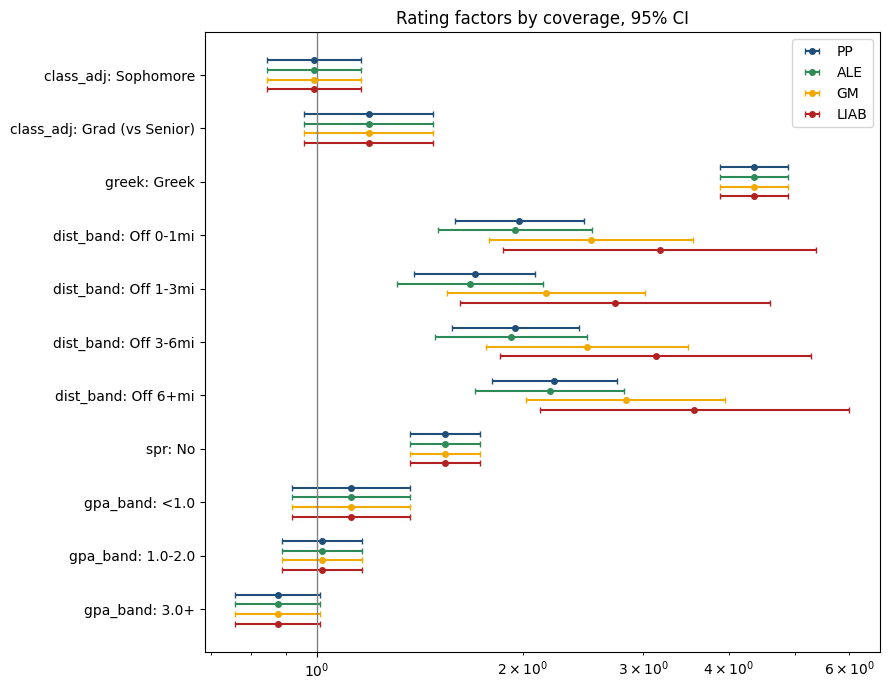

In [27]:
labels = list(dict.fromkeys(rel["variable"] + ": " + rel["level"]))
y = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(9, 7))
for i, (c, color) in enumerate(zip(COV_ORDER, ["#1f4e79", "#2e8b57", "#f2a900", "#b22222"])):
    d = rel[rel["cov"].eq(c)]
    ax.errorbar(d["factor"], y + (i - 1.5) * 0.18, xerr=[d["factor"] - d["lo95"], d["hi95"] - d["factor"]],
                fmt="o", color=color, label=c, capsize=2, ms=4)
ax.axvline(1, color="grey", lw=1)
ax.set_xscale("log")
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_title("Rating factors by coverage, 95% CI")
ax.legend()
plt.tight_layout()
plt.show()

### Export for the Excel pricing model

In [28]:
base_rates.to_csv("base_loss_by_tier.csv")
factors.to_csv("rating_factors.csv")